In [ ]:
# Repo bootstrap: notebooks use paths relative to the repo root and import from src/
import os, sys
from pathlib import Path

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "pipeline.py").exists())
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))

In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import cv2
import shutil
import torch.nn as nn
import os
import pandas as pd
import random

from PatchDataset import load_dataset
from torch.utils.data import DataLoader,Subset,Dataset
from torchvision import datasets, transforms
from PIL import Image
from tqdm import tqdm
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.metrics import (
    roc_curve, auc,
    precision_recall_curve, average_precision_score
)
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report, confusion_matrix
from transformers import CLIPProcessor, CLIPModel

from PatchDataset import load_dataset,load_augmented_dataset
from pipeline import set_seed,predict_probs, eval_clip,compute_binary_metrics


In [2]:
PATCH_SIZE = 224
BATCH_SIZE = 32
SEED = 42
set_seed(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

PATCHES_ROOT = "patches_dataset/patches_v3_seed42_pad1.6_iouth0.09"
traincsv_path = os.path.join(PATCHES_ROOT, "metadata.csv")
testcsv_path = "patches_dataset/test_patches_v3/test_metadata.csv"


cpu


In [3]:
# loading the dataset
traindf = pd.read_csv(traincsv_path)
traindf["patch_id"] = traindf["patch_id"].astype(int)
traindf["label"] = traindf["label"].astype(int)
traindf["type"] = traindf["type"].astype(str)

testdf = pd.read_csv(testcsv_path)
testdf["patch_id"] = testdf["patch_id"].astype(int)
testdf["label"] = testdf["label"].astype(int)
testdf["type"] = testdf["type"].astype(str)

train_dataset,val_dataset,train_loader,val_loader,test_dataset,test_loader = load_dataset(traindf,testdf,PATCHES_ROOT,BATCH_SIZE)

for xb,yb in train_loader:
    print(xb.shape,yb.shape,min(yb),max(yb))
    break

AUG_ROOT_v3 = "patches_dataset/patches_v3_train_aug"
PATH_AUG_METADATA_v3 = os.path.join(AUG_ROOT_v3, "metadata.csv")

aug_train_datasetv3,aug_val_datasetv3,aug_train_loaderv3,aug_val_loaderv3,aug_test_datasetv3,aug_test_loaderv3 = load_augmented_dataset(
    PATCHES_ROOT,
    AUG_ROOT_v3,
    PATH_AUG_METADATA_v3,
    testcsv_path,
    BATCH_SIZE
)

AUG_ROOT_v4 = "patches_dataset/patches_v4_train_aug"
PATH_AUG_METADATA_v4 = os.path.join(AUG_ROOT_v4, "metadata.csv")

aug_train_datasetv4,aug_val_datasetv4,aug_train_loaderv4,aug_val_loaderv4,aug_test_datasetv4,aug_test_loaderv4 = load_augmented_dataset(
    PATCHES_ROOT,
    AUG_ROOT_v4,
    PATH_AUG_METADATA_v4,
    testcsv_path,
    BATCH_SIZE
)




train/val: 15858 3965
torch.Size([32, 3, 224, 224]) torch.Size([32]) tensor(0) tensor(1)
train_aug/test: 25372 3965
train_aug/test: 31716 3965


In [4]:
def plot_random_images(dataset, num_images, images_per_row,name):
    pos_indices = [i for i in range(len(dataset)) if dataset[i][1] == 1]
    neg_indices = [i for i in range(len(dataset)) if dataset[i][1] == 0]

    n_pos = min(num_images, len(pos_indices))
    n_neg = min(num_images, len(neg_indices))

    pos_samples = random.sample(pos_indices, n_pos) if n_pos > 0 else []
    neg_samples = random.sample(neg_indices, n_neg) if n_neg > 0 else []

    all_indices = pos_samples + neg_samples
    total_images = len(all_indices)

    num_rows = (total_images + images_per_row - 1) // images_per_row
    fig, axes = plt.subplots(num_rows, images_per_row, figsize=(images_per_row * 3, num_rows * 3))

    if num_rows == 1 and images_per_row == 1:
        axes = [[axes]]
    elif num_rows == 1:
        axes = [axes]
    elif images_per_row == 1:
        axes = [[ax] for ax in axes]

    for i, idx in enumerate(all_indices):
        row = i // images_per_row
        col = i % images_per_row
        img, label = dataset[idx]
        img = img.permute(1, 2, 0).numpy()

        axes[row][col].imshow(img)
        axes[row][col].set_title(f"Label: {'pos' if label == 1 else 'neg'}")
        axes[row][col].axis('off')

    for i in range(total_images, num_rows * images_per_row):
        row = i // images_per_row
        col = i % images_per_row
        axes[row][col].axis('off')

    plt.tight_layout()
    plt.savefig(f"images/dataset_exs_{name}")
    plt.show()

# Normal dataset v3

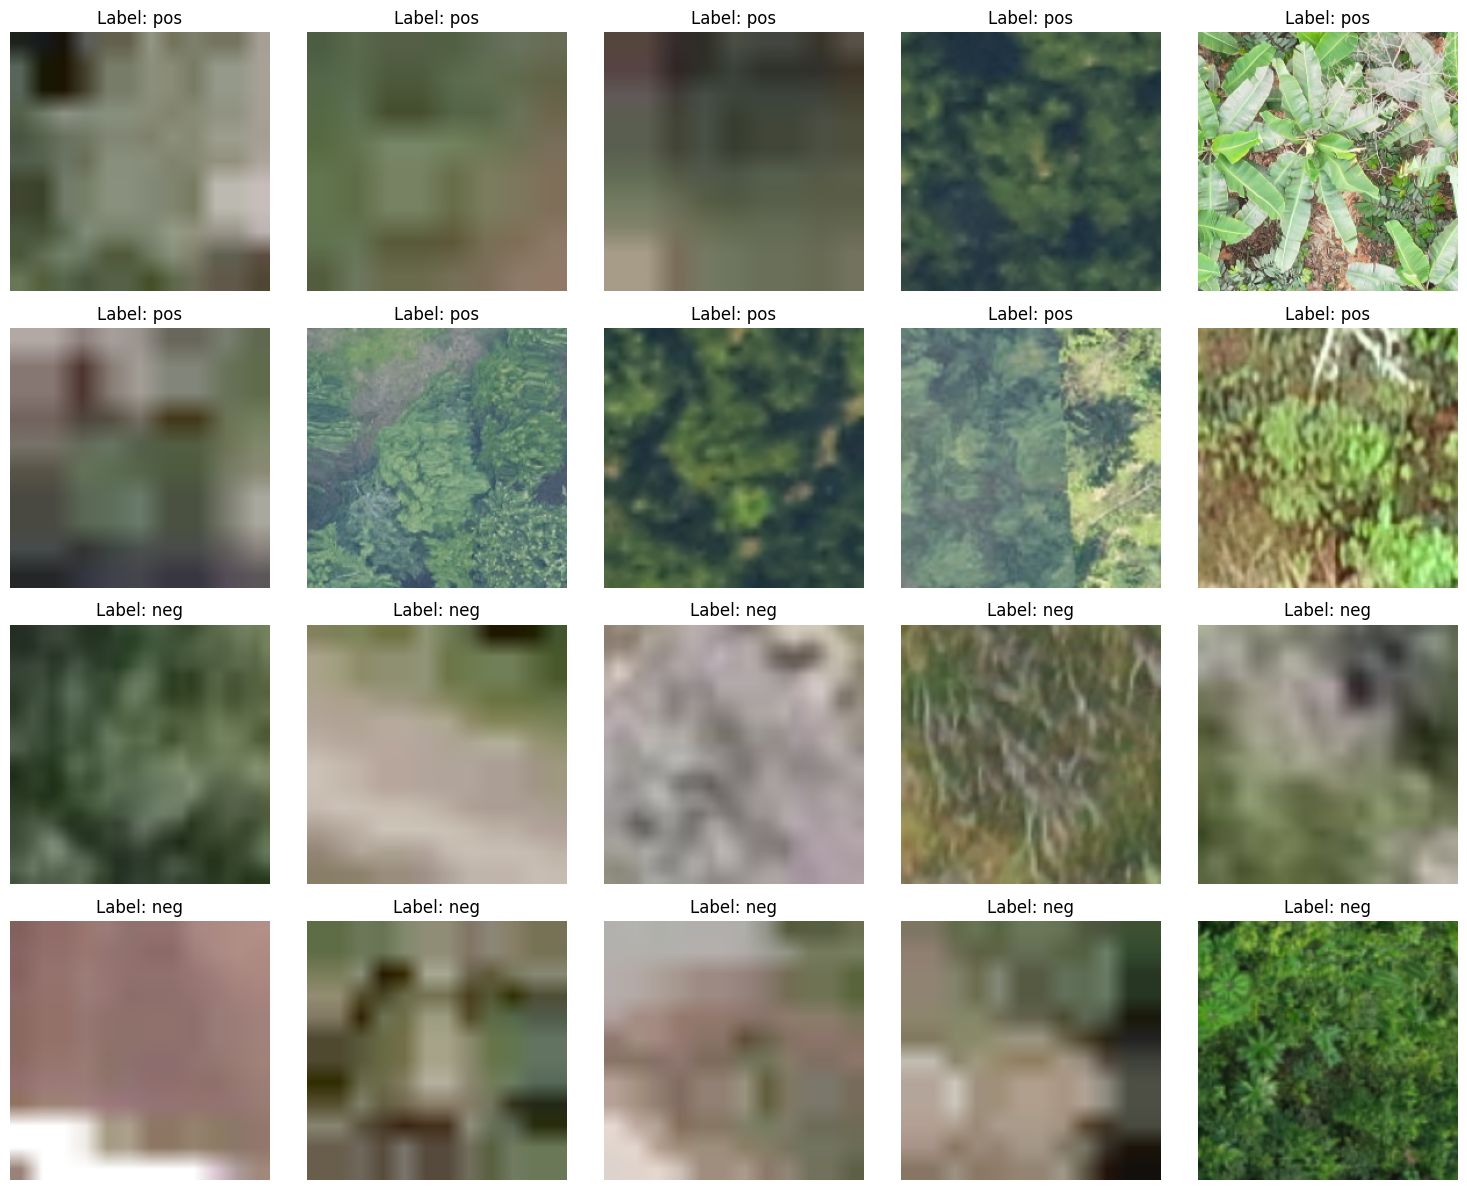

In [5]:
plot_random_images(train_dataset,10,5,"normalv3")

# v3 augmented

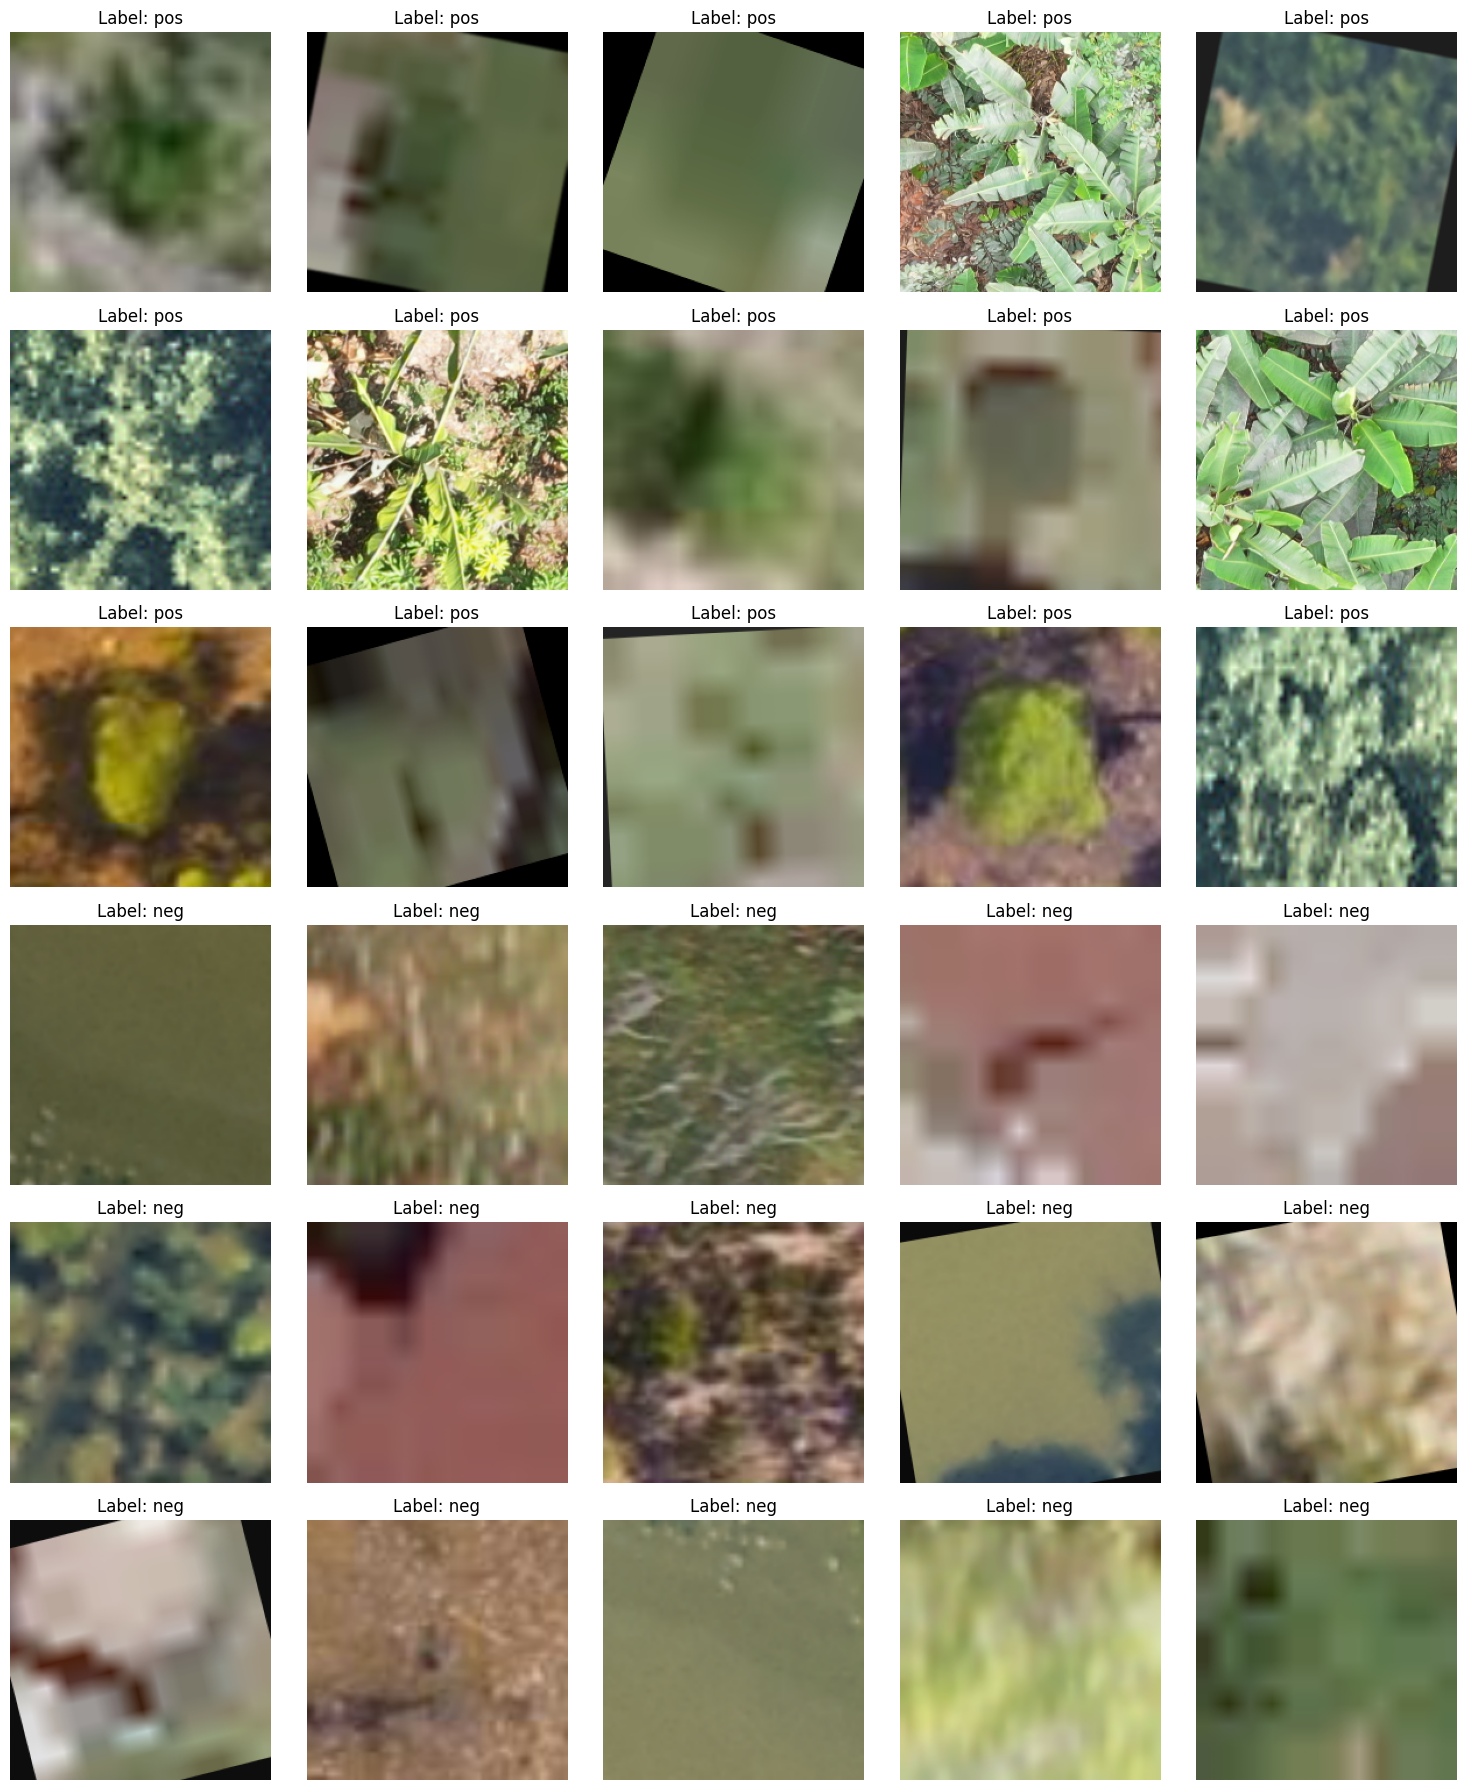

In [12]:
plot_random_images(aug_train_datasetv3,15,5,"augv3")

# v4 augmente

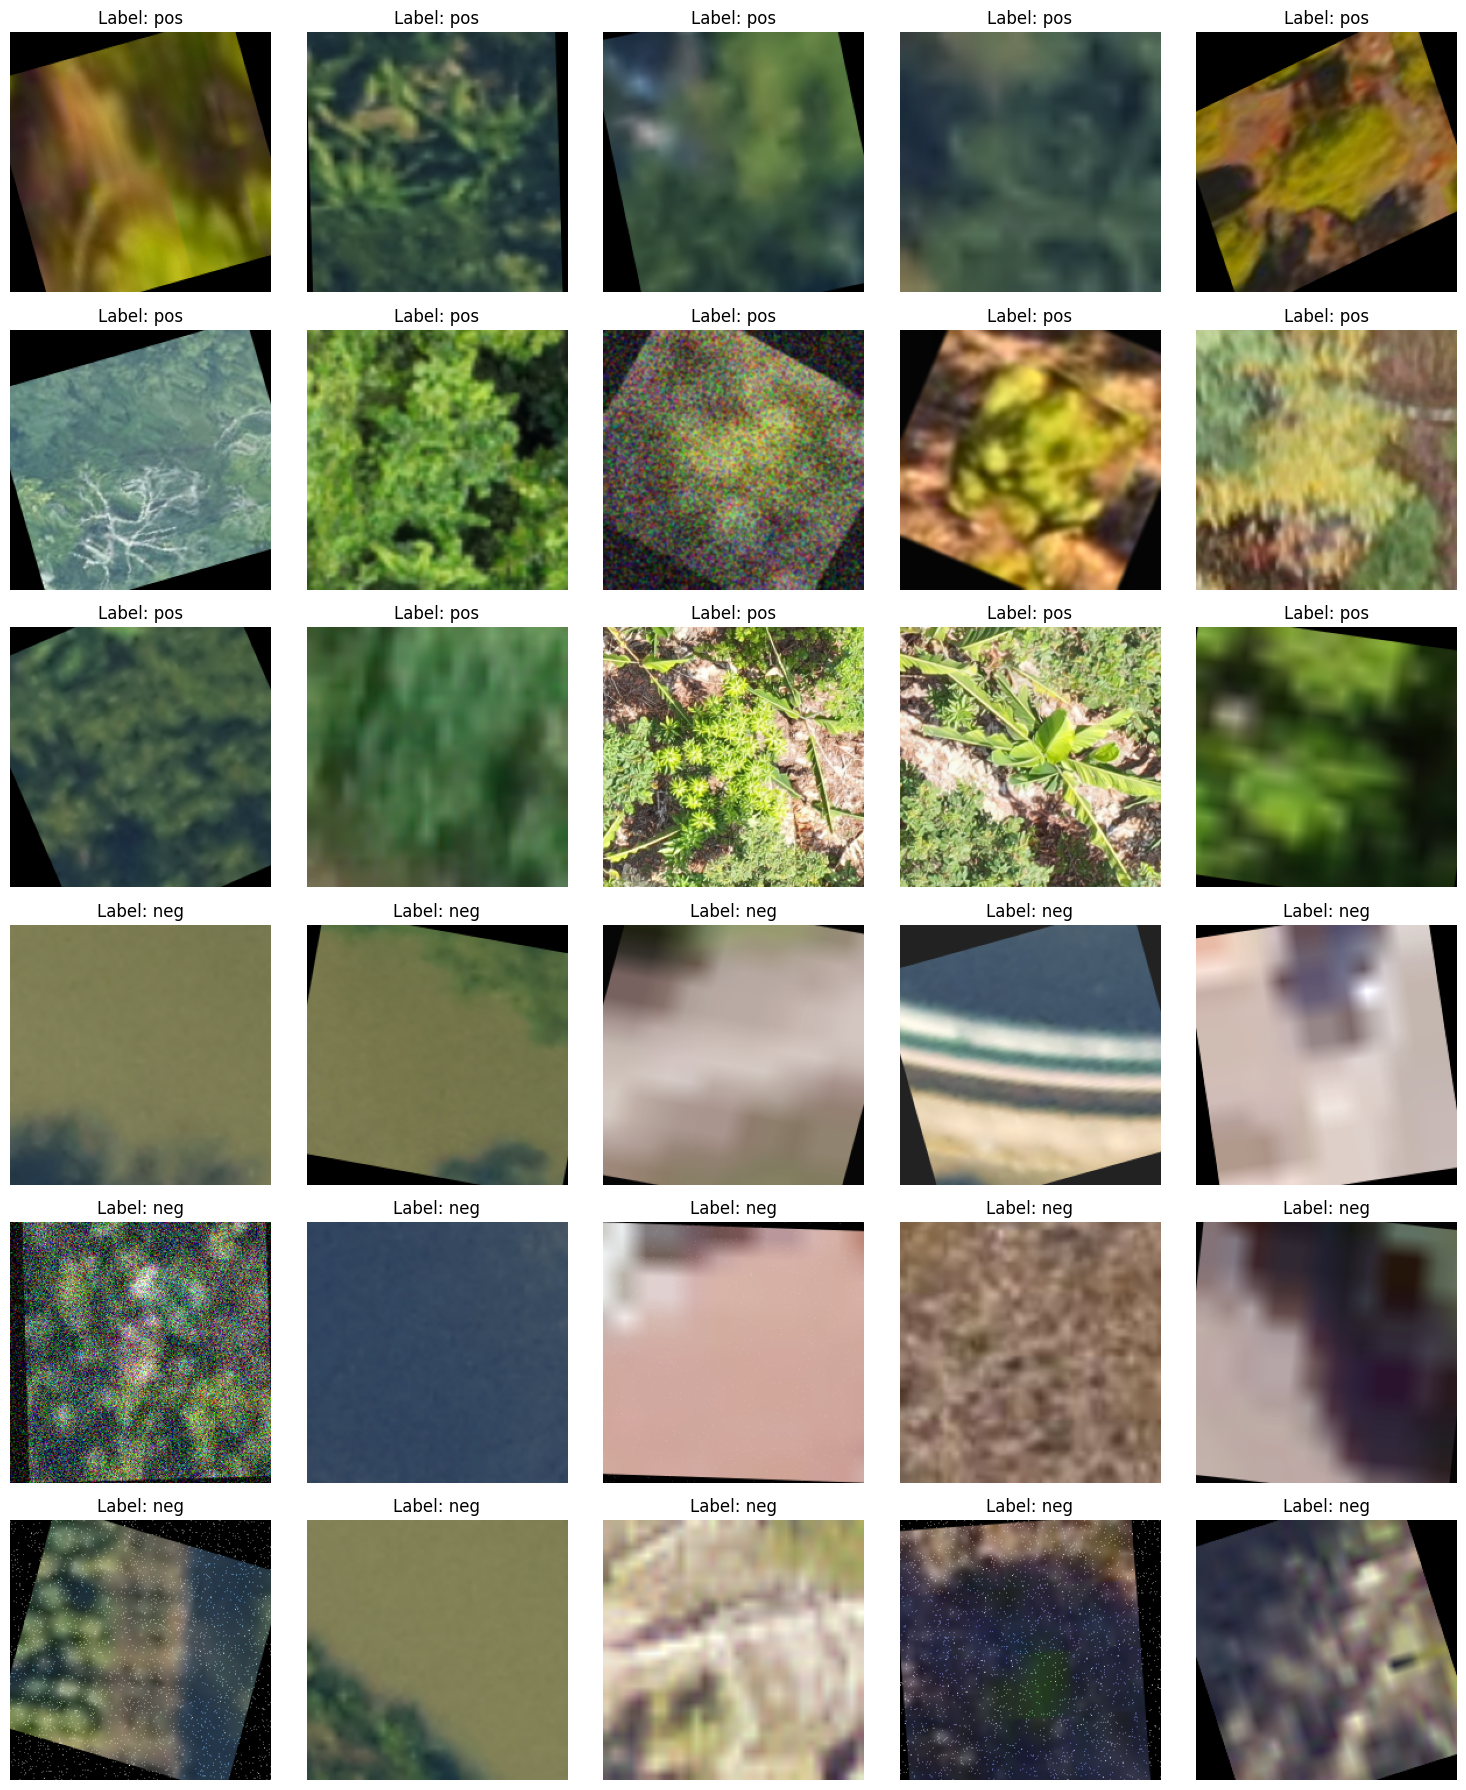

In [27]:
plot_random_images(aug_train_datasetv4,15,5,"augv4")

In [6]:
## without using the plot_random_images function, visualize random patches examples from the datasets and save the images to the "images/report/patches" folder. The images should be saved with the name "patch_{dataset}_{i}.pdf".
def save_random_patches(dataset, num_images, name):
    os.makedirs("images/report/patches", exist_ok=True)  # Create dir if missing
    
    pos_indices = [i for i in range(len(dataset)) if dataset[i][1] == 1]
    neg_indices = [i for i in range(len(dataset)) if dataset[i][1] == 0]

    n_pos = min(num_images, len(pos_indices))
    n_neg = min(num_images, len(neg_indices))

    pos_samples = random.sample(pos_indices, n_pos) if n_pos > 0 else []
    neg_samples = random.sample(neg_indices, n_neg) if n_neg > 0 else []

    all_indices = pos_samples + neg_samples
    k = 0
    for i, idx in enumerate(all_indices):
        k += 1
        print(k)
        img, label = dataset[idx]
        img = img.permute(1, 2, 0).numpy()
        plt.figure(figsize=(4, 4))  # Add explicit figure for safety
        plt.imshow(img)
        plt.title(f"Label: {'pos' if label == 1 else 'neg'}")
        plt.axis('off')
        plt.savefig(f"images/report/patches/patch_{name}_{i}.pdf", bbox_inches='tight', dpi=150)
        plt.close('all')  # Close all figs to free memory



In [9]:
#save_random_patches(train_dataset,10,"normalv3")
#save_random_patches(aug_train_datasetv3,10,"augv3")
save_random_patches(aug_train_datasetv4,10,"augv4")

1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
